## Renewal Model: Logistic Regression

## The question
Which season ticket members are likely to **cancel**, and **what drives** that decision?

## Why logistic regression?
Renewal is a **yes/no outcome** (1 = renewed, 0 = cancelled). Logistic regression predicts
the **probability** of a yes/no outcome.


## Key terms
| Term | Meaning |
|---|---|
| **Odds** | Chance of renewing ÷ chance of cancelling. 80% renew → 0.8 / 0.2 = 4 to 1. |
| **Odds ratio** | How much a feature multiplies the odds. **> 1** = more likely to renew, **< 1** = less likely, **1** = no effect. |
| **Baseline** | For categories, one value is left out as the comparison point (e.g. Red is compared to Green). |
| **AUC** | How well the model **ranks** members by risk. 0.5 = coin flip, 1.0 = perfect. If you pick one renewer and one canceller at random, AUC is the chance the model gives the renewer the higher score. |
| **Cross-validation** | Train and test on 5 different splits and average the results, which is more reliable than one split with only ~38 cancellations. |
| **Threshold** | The risk cutoff for flagging a member "at risk." Lower catches more cancellers but creates more false alarms. |

## How it connects to the k-means segments
K-means found **who** our members are (segments). Logistic regression scores **how likely
each member is to cancel** and **why**. Combined, they show which segments hold the most
risk and revenue, so the retention team knows who to call first.

## Baselines in this model (what each category is compared to)
- Ticket_Type: **Full Season**
- Payment_Status: **Green**
- Payment_Plan: **12 Monthly**
- Account_Type: **Corporate**
- Seating_Area: **BALCONY**
- State: **NJ**


In [11]:
# Load Libraries and Data 
from pathlib import Path 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
model_df = pd.read_csv(PROCESSED_DATA / "model_df.csv")
print(model_df.shape) # (888,26)


(888, 26)


In [12]:
# BUILD FEATURE TABLE 

# Choose Features and Turn Categories into 0/1 Columns
numeric_features  = ["resale_rate", "forward_rate", "no_show_rate", "concerts_bought",
                     "tenure_years", "Price_Per_Seat", "Num_Seats", "Age"]
category_features = ["Ticket_Type", "Payment_Plan", "Payment_Status",
                     "Account_Type", "Seating_Area", "State"]

def build_features(df, numeric_cols, category_cols):
    """Fill missing numbers with the median, then turn categories into 0/1 columns."""
    X = df[numeric_cols + category_cols].copy()
    X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())   # Age has 79 blanks
    return pd.get_dummies(X, columns=category_cols, drop_first=True, dtype=int)

X = build_features(model_df, numeric_features, category_features)
y = model_df["renewed"]

print(X.shape, "| renewal rate:", y.mean().round(3))     # (888, 21) | 0.829
X.columns.tolist()



(888, 21) | renewal rate: 0.829


['resale_rate',
 'forward_rate',
 'no_show_rate',
 'concerts_bought',
 'tenure_years',
 'Price_Per_Seat',
 'Num_Seats',
 'Age',
 'Ticket_Type_Half Season',
 'Ticket_Type_Quarter Season',
 'Payment_Plan_3 Way',
 'Payment_Plan_5-6 Month',
 'Payment_Plan_Pay in Full',
 'Payment_Status_Red',
 'Payment_Status_Yellow',
 'Account_Type_Individual',
 'Seating_Area_LOWER',
 'State_NY',
 'State_PA',
 'State_Unknown',
 'State_VT']

In [13]:
# Model Recipe: scale the numbers, then fit logistic regression
def make_model(numeric_cols):
    scale_numbers_only = ColumnTransformer([("scale", StandardScaler(), numeric_cols)],
                                           remainder="passthrough")   # 0/1 columns stay as-is
    return Pipeline([("prep", scale_numbers_only),
                     ("logreg", LogisticRegression(max_iter=1000))])

In [14]:
# Split, Train, and Score with AUC
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

model = make_model(numeric_features)
model.fit(X_train, y_train)

renew_prob_test = model.predict_proba(X_test)[:, 1]
print("Test AUC:", round(roc_auc_score(y_test, renew_prob_test), 3))

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(make_model(numeric_features), X, y, cv=folds, scoring="roc_auc")
print("5-fold AUC:", cv_auc.round(3), "| mean:", round(cv_auc.mean(), 3))

Test AUC: 0.657
5-fold AUC: [0.726 0.78  0.722 0.708 0.69 ] | mean: 0.725


In [15]:
# Flag Members at 25%+ Risk of Cancelling
churn_risk_test = 1 - renew_prob_test
flagged   = (churn_risk_test >= 0.25).astype(int)
cancelled = 1 - y_test

print(pd.DataFrame(confusion_matrix(cancelled, flagged),
                   index=["Actually renewed", "Actually cancelled"],
                   columns=["Not flagged", "Flagged at risk"]))
print(classification_report(cancelled, flagged, target_names=["Renewed", "Cancelled"]))

                    Not flagged  Flagged at risk
Actually renewed            156               28
Actually cancelled           24               14
              precision    recall  f1-score   support

     Renewed       0.87      0.85      0.86       184
   Cancelled       0.33      0.37      0.35        38

    accuracy                           0.77       222
   macro avg       0.60      0.61      0.60       222
weighted avg       0.78      0.77      0.77       222



In [16]:
# Odds Ratios: What Drives Renewal
feature_names = model.named_steps["prep"].get_feature_names_out()
coefs = model.named_steps["logreg"].coef_[0]

odds = pd.DataFrame({"feature": feature_names, "odds_ratio": np.exp(coefs)})
odds["feature"] = odds["feature"].str.replace("scale__", "").str.replace("remainder__", "")
odds = odds.sort_values("odds_ratio")
odds.round(2)

,feature,odds_ratio
13,Payment_Status_Red,0.11
9,Ticket_Type_Quarter Season,0.27
14,Payment_Status_Yellow,0.29
8,Ticket_Type_Half Season,0.50
2,no_show_rate,0.64
11,Payment_Plan_5-6 Month,0.67
5,Price_Per_Seat,0.78
0,resale_rate,0.81
12,Payment_Plan_Pay in Full,0.89
1,forward_rate,0.93


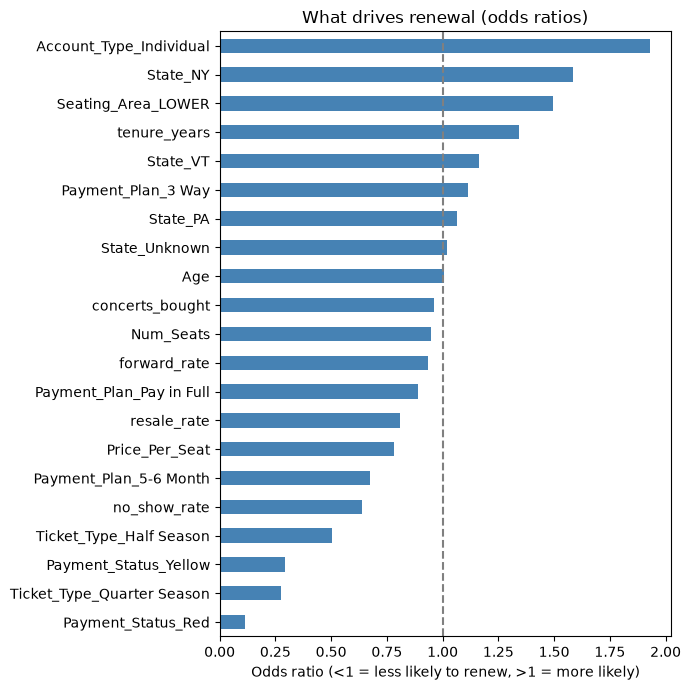

In [17]:
# Odds Plotted

ax = odds.plot(x="feature", y="odds_ratio", kind="barh", figsize=(7, 7), legend=False, color="steelblue")
ax.axvline(1, color="gray", linestyle="--")
ax.set(title="What drives renewal (odds ratios)",
       xlabel="Odds ratio (<1 = less likely to renew, >1 = more likely)", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Compare Models: With and Without K-Means Segments
X_with_segment = build_features(model_df, numeric_features, category_features + ["segment_name"])
X_segment_only = pd.get_dummies(model_df[["segment_name"]], drop_first=True, dtype=int)

for name, X_version, nums in [("Behavior + profile", X, numeric_features),
                              ("Segment label only", X_segment_only, []),
                              ("Behavior + profile + segment", X_with_segment, numeric_features)]:
    scores = cross_val_score(make_model(nums), X_version, y, cv=folds, scoring="roc_auc")
    print(f"{name:<30} AUC {scores.mean():.3f}")

Behavior + profile             AUC 0.725
Segment label only             AUC 0.621
Behavior + profile + segment   AUC 0.716


In [19]:
# Score Every Member and Summarize Risk by Segment
renew_prob_all = cross_val_predict(make_model(numeric_features), X, y, cv=folds,
                                   method="predict_proba")[:, 1]
model_df["churn_risk"] = 1 - renew_prob_all

games_in_plan = model_df["Ticket_Type"].map({"Full Season": 41, "Half Season": 20.5, "Quarter Season": 10})
model_df["season_value"]    = model_df["Price_Per_Seat"] * model_df["Num_Seats"] * games_in_plan
model_df["revenue_at_risk"] = model_df["churn_risk"] * model_df["season_value"]

print("Missing season values:", model_df["season_value"].isna().sum())   # should be 0

segment_risk = (model_df.groupby("segment_name")
                .agg(accounts=("Account_ID", "size"),
                     actual_renewal_rate=("renewed", "mean"),
                     avg_churn_risk=("churn_risk", "mean"),
                     high_risk_accounts=("churn_risk", lambda risk: (risk >= 0.25).sum()),
                     revenue_at_risk=("revenue_at_risk", "sum"))
                .sort_values("avg_churn_risk", ascending=False))
segment_risk.round(2)

Missing season values: 0


,accounts,actual_renewal_rate,avg_churn_risk,high_risk_accounts,revenue_at_risk
segment_name,,,,,
Resellers & Absentees,94,0.63,0.36,60,1469506.26
Newer Core Members,477,0.82,0.18,99,2355106.12
Concert Add-On Fans,104,0.84,0.15,13,418549.58
Loyal Veterans,213,0.92,0.08,9,371556.21


In [20]:
# Retention Call List: Top 15 by Revenue at Risk
call_list = (model_df.sort_values("revenue_at_risk", ascending=False)
             [["Account_ID", "segment_name", "State", "Payment_Status",
               "churn_risk", "season_value", "revenue_at_risk"]]
             .head(15))
call_list.to_csv(PROCESSED_DATA / "retention_call_list.csv", index=False)

print("Total revenue at risk: $", round(model_df["revenue_at_risk"].sum()))
call_list.round(2)

Total revenue at risk: $ 4614718


,Account_ID,segment_name,State,Payment_Status,churn_risk,season_value,revenue_at_risk
366,ACCT100380,Resellers & Absentees,NY,Green,0.56,132840.00,73874.87
395,ACCT100410,Resellers & Absentees,VT,Green,0.53,134808.00,71393.08
165,ACCT100173,Newer Core Members,NY,Red,0.65,106600.00,68848.19
874,ACCT100902,Newer Core Members,NY,Red,0.39,173184.00,68008.13
316,ACCT100327,Resellers & Absentees,NY,Green,0.38,149814.00,56265.62
525,ACCT100545,Resellers & Absentees,NY,Yellow,0.76,73144.00,55562.51
646,ACCT100669,Resellers & Absentees,NY,Green,0.45,119802.00,53491.00
217,ACCT100226,Loyal Veterans,NY,Red,0.25,199752.00,49235.21
408,ACCT100424,Resellers & Absentees,PA,Green,0.66,73144.00,48520.75
820,ACCT100846,Resellers & Absentees,NY,Green,0.34,139728.00,47811.11


## Renewal Model Findings
- Logistic regression ranks renewal risk with a **cross-validated AUC of 0.73**.
- **Biggest drivers (odds ratios):**
  - Red payment status: ~89% lower odds of renewing than Green; Yellow ~71% lower
  - Quarter and Half Season plans renew less than Full Season
  - Higher no-show rates lower renewal
  - Longer tenure, Individual accounts and Lower-level seats raise renewal
- **Combining with k-means:** adding the segment label didn't improve the model
  (0.716 vs. 0.725), since segments are built from the same behaviors. Instead, the
  model scores risk and the segments explain who is at risk:
  - Resellers & Absentees: 2x average churn risk (36%), ~$1.5M revenue at risk
  - Newer Core Members: most total revenue at risk (~$2.4M) because of their size
- **Action:** a 15-account call list ranked by revenue at risk.
- **Limitation:** at a 25% risk threshold the model catches ~37% of cancellers.
  It's best for prioritizing outreach, not as a yes/no prediction.